In [4]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features, models


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
# Sélection du scope de données à traiter (sources, défauts, diamètres, positions, charges, canaux)
selection = data.selectionner(
    sources=("12kDE", "Normal"),
    defauts=("IR", "B", "OR"),
    diametres=(7, 14, 21), positions_or=("6",),
    charges=(0, 1, 2, 3),
    canaux={"12kDE": ("DE",), 
            "Normal": ("DE")},
)

In [6]:
import numpy as np
import pandas as pd
from Sources.data import selectionner, charger

# Constructions des fenetres de signaux BRUTES : signaux + infos

def fenetre_brute(x, taille=1024, recouvrement=0.5):
    """Decoupe chaque signal en fenetres de taille paramétrable avec recouvrement (50 % par defaut)."""
    pas = int(taille * (1 - recouvrement))
    return [x[i:i + taille] for i in range(0, len(x) - taille + 1, pas)]

def construire_fenetres_brutes(selection, canal="DE", taille=1024):
    """Renvoie (SBNorm, infos) :
       SBNorm    : array (n_fenetres, taille), chaque fenetre 
       infos : DataFrame, une ligne par fenetre (pour le split et l'evaluation)
    """
    SBNorm, lignes = [], []
    for nom, info in selection.iterrows():          # Fichiers depuis sélection
        s = charger(nom)                             # signal brut
        signBrute = s[canal]
        for i, val in enumerate(fenetre_brute(signBrute, taille)):
            SBNorm.append((val - val.mean()) / val.std()) # normalisation par fenetre
            lignes.append({"fichier": nom, "fenetre": i, "canal": canal,
                           "defaut": info["defaut"], "charge_hp": info["charge_hp"],
                           "rpm": s["rpm"], "fs": s["fs"]})
    return np.array(SBNorm, dtype=np.float32), pd.DataFrame(lignes)

# Exemple : plan 12 kHz cote moteur, comme dans votre rapport
selection = selectionner()                       # 40 fichiers (sains + defauts)
SBNorm, infos = construire_fenetres_brutes(selection, canal="DE", taille=1024)

# Fenêtres et recouvrement
On créer des fenêtres dans le signal pour avoir d'avantage de données d'entrainement (comme précédement).
On veille à avoir des fenêtres assez longue pour ne pas perdre d'informations :
    Une fenêtre de 1024 points à 12 kHz dure environ 85 ms, soit environ 5 périodes de BPFO, donc assez pour capter la fréquence des chocs.

Le recouvrement sert à mieux capter les chocs :
Sans recouvrement, un choc de défaut qui tombe à cheval sur le partage de deux fenêtres est vue "à moitié" dans chaque fenêtre, le modèle verrait donc moins bien l'événement "choc". Avec du recouvrement, chaque événement apparaît complet dans au moins une fenêtre, on ne perd pas d'information.


# Normalisation des fenetres
On normalise le signal brute **(val - val.mean()) / val.std()** car l'amplitude varie avec la charge. 
Si la charge augmente, l'amplitude du signal (de la fenêtre) augmente, et le modèle va détecter une variation et donc un défaut, hors l'augmentation de charge , n'est pas un défaut !
Le fait de normaliser donne des échelles d'amplitudes similaires, donc le modèle ne verra que :
 - amplitude proche de 0 > Sain 
 - amplitude proche de 1 > Défaut
peu importe la charge.

In [8]:
# ---------------------------------------------------------------
# 2. Split PAR FICHIER (anti-fuite) + masque "sain" pour l'entrainement
# ---------------------------------------------------------------
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
i_train, i_test = next(gss.split(infos, groups=infos["fichier"]))   # jamais de fenetres d'un meme fichier des deux cotes

sain = (infos["defaut"] == "Sain").to_numpy()
X_train_sain = SBNorm[i_train][sain[i_train]]         # l'AE n'apprend QUE le comportement sain

In [9]:
# ---------------------------------------------------------------
# 3. Conv1D-AE minimal (Keras) + score d'anomalie = MSE
# ---------------------------------------------------------------
import tensorflow as tf
import keras
from keras import layers

def conv1d_ae(taille=1024):
    Input = keras.Input(shape=(taille, 1))
    # ---- encodeur : 2 poolings, 1024 -> 512 -> 256 ----
    x = layers.Conv1D(32, 7, activation="relu", padding="same")(Input)   # 1024
    x = layers.MaxPooling1D(2, padding="same")(x)                         # 512
    x = layers.Conv1D(16, 5, activation="relu", padding="same")(x)        # 512
    x = layers.MaxPooling1D(2, padding="same")(x)                         # 256
    latent = layers.Conv1D(8, 3, activation="relu", padding="same")(x)    # 256 = bottleneck
    # ---- decodeur : miroir exact, 2 upsamplings, 256 -> 512 -> 1024 ----
    x = layers.Conv1D(16, 5, activation="relu", padding="same")(latent)  # 256
    x = layers.UpSampling1D(2)(x)                                         # 512
    x = layers.Conv1D(32, 7, activation="relu", padding="same")(x)        # 512
    x = layers.UpSampling1D(2)(x)                                         # 1024
    sortie = layers.Conv1D(1, 7, padding="same")(x)                       # 1024, 1 canal
    modele = keras.Model(Input, sortie)
    modele.compile(optimizer="adam", loss="mse")
    return modele


I0000 00:00:1794500907.353814    8309 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [10]:
modele = conv1d_ae(taille=1024)
hist = modele.fit(X_train_sain[..., None], X_train_sain[..., None], epochs=20, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/20
 1/20 ━━━━━━━━━━━━━━━━━━━━ 1:01 3s/step - loss: 1.0146

W0000 00:00:1794500921.170844    8933 cpu_allocator_impl.cc:174] Allocation of 32112640 exceeds 10% of free system memory.
W0000 00:00:1794500921.170782    8932 cpu_allocator_impl.cc:174] Allocation of 32112640 exceeds 10% of free system memory.
W0000 00:00:1794500921.210523    8932 cpu_allocator_impl.cc:174] Allocation of 23396352 exceeds 10% of free system memory.
W0000 00:00:1794500921.210580    8933 cpu_allocator_impl.cc:174] Allocation of 23396352 exceeds 10% of free system memory.
W0000 00:00:1794500921.222309    8932 cpu_allocator_impl.cc:174] Allocation of 26296320 exceeds 10% of free system memory.


20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 125ms/step - loss: 0.8343 - val_loss: 0.5540
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step - loss: 0.3357 - val_loss: 0.3042
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step - loss: 0.1976 - val_loss: 0.2137
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - loss: 0.1449 - val_loss: 0.1458
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - loss: 0.0845 - val_loss: 0.0495
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - loss: 0.0381 - val_loss: 0.0354
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step - loss: 0.0280 - val_loss: 0.0275
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - loss: 0.0233 - val_loss: 0.0238
Epoch 9/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - loss: 0.0206 - val_loss: 0.0210
Epoch 10/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - loss: 0.0196 - val_loss: 0.0193
Epoch 11/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - loss: 0.0180 - val_loss: 0.0173
Epoch 12/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 136ms/step - loss: 0.0160 - 

In [12]:
# score d'anomalie : erreur de reconstruction par fenetre
def score_anomalie(modele, SBNorm):
    Xr = modele.predict(SBNorm[..., None], verbose=1)[..., 0]
    return ((SBNorm - Xr) ** 2).mean(axis=1)

infos["score"] = score_anomalie(modele, SBNorm)
seuil = np.percentile(infos["score"].to_numpy()[i_train][sain[i_train]], 99)  # percentile 99 des sains du train
infos["alarme"] = infos["score"] > seuil

370/370 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step


In [14]:
# ---------------------------------------------------------------
# 4. Evaluation simple sur le test : sain vs defaut
# ---------------------------------------------------------------
from sklearn.metrics import roc_auc_score

y_test = (infos["defaut"].to_numpy()[i_test] != "Sain")     # 0 = sain, 1 = defaut
auc = roc_auc_score(y_test, infos["score"].to_numpy()[i_test])
print(f"ROC-AUC detection sain/defaut : {auc:.3f}")

ROC-AUC detection sain/defaut : 1.000


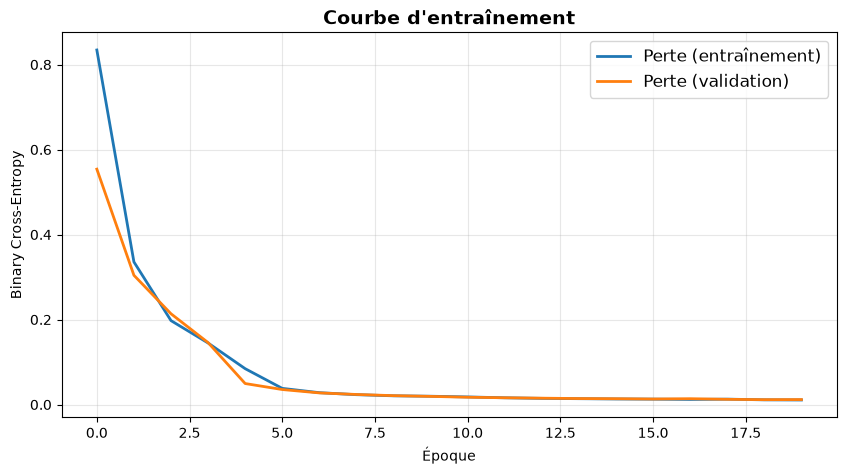

In [15]:
plt.figure(figsize=(10, 5))
plt.plot(hist.history["loss"], label="Perte (entraînement)", linewidth=2)
plt.plot(hist.history["val_loss"], label="Perte (validation)", linewidth=2)
plt.xlabel("Époque")
plt.ylabel("Binary Cross-Entropy")
plt.title("Courbe d'entraînement", fontsize=14, fontweight="bold")
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()